# Лабораторная работа №1

## Задания

![Задания](./tasks.png "Задания")

## Библиотеки

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Реализация

In [2]:
df = pd.read_csv("series.csv", parse_dates=["timestamp"]).set_index("timestamp")
df.head()

,value
timestamp,
2026-11-15 00:00:00,83.224526
2026-11-15 00:05:00,82.807885
2026-11-15 00:10:00,67.497676
2026-11-15 00:15:00,89.902682
2026-11-15 00:20:00,101.061432


In [3]:
full_idx = pd.date_range(df.index.min(), df.index.max(), freq="h")
df = df.reindex(full_idx)
df.index.name = "timestamp"
df.head()

,value
timestamp,
2026-11-15 00:00:00,83.224526
2026-11-15 01:00:00,61.910660
2026-11-15 02:00:00,84.952187
2026-11-15 03:00:00,79.360228
2026-11-15 04:00:00,82.905316


In [4]:
df["rolling_mean"] = df["value"].rolling(24).mean()
df["rolling_std"] = df["value"].rolling(24).std()
df.head()

,value,rolling_mean,rolling_std
timestamp,,,
2026-11-15 00:00:00,83.224526,NaN,NaN
2026-11-15 01:00:00,61.910660,NaN,NaN
2026-11-15 02:00:00,84.952187,NaN,NaN
2026-11-15 03:00:00,79.360228,NaN,NaN
2026-11-15 04:00:00,82.905316,NaN,NaN


In [5]:
q1, q3 = df["value"].quantile([0.25, 0.75])
iqr = q3 - q1
df["outlier_iqr"] = (df["value"] < q1 - 1.5 * iqr) | (df["value"] > q3 + 1.5 * iqr)
df.head()

,value,rolling_mean,rolling_std,outlier_iqr
timestamp,,,,
2026-11-15 00:00:00,83.224526,NaN,NaN,False
2026-11-15 01:00:00,61.910660,NaN,NaN,False
2026-11-15 02:00:00,84.952187,NaN,NaN,False
2026-11-15 03:00:00,79.360228,NaN,NaN,False
2026-11-15 04:00:00,82.905316,NaN,NaN,False


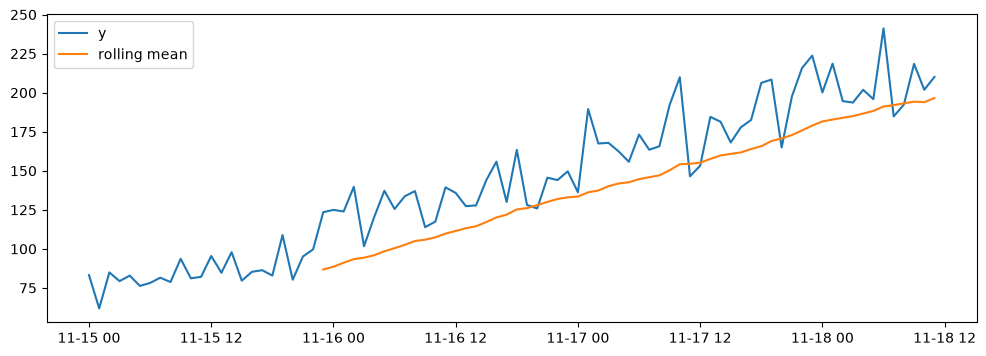

In [7]:
plt.figure(figsize=(12, 4))
plt.plot(df.index, df["value"], label="y")
plt.plot(df.index, df["rolling_mean"], label="rolling mean")
plt.legend()
plt.show()